# 07 Extensions: timing, forecasting, other assets and robustness

Four follow-ups to notebooks 04 to 06:

1. Six-month rolling windows, so the 2008 and 2020 crises are not split across calendar years.
2. An out-of-sample test of the risk claim: calibrate a risk model on one year and see how far it misses the next.
3. Treasuries and gold against the S&P 500, to check whether protection really comes from outside the index.
4. Two harder versions of the null test in notebook 06: fat-tailed noise, and a market-plus-sector model.

In [1]:
import sys
sys.path.insert(0, "..")

import pandas as pd
from IPython.display import Image

import src.cross_asset as cross_asset
import src.oos_risk as oos_risk
import src.rolling as rolling

## 1. Rolling windows

Each window covers the six months up to a month end and moves forward one month at a time. Volatility is annualised so that the sparse pre-2019 windows and the complete later ones are on the same scale.

In [2]:
rolling_frame = rolling.main()

windows: 246; peak 0.662 in the window ending Dec 2011; low 0.106 ending Nov 2017
correlation at typical volatility: 0.221 to 0.317

around Lehman (window ends):
            n_obs  mean_corr  market_vol
end                                     
2008-03-31     60     0.3789      0.2350
2008-04-30     53     0.3918      0.2424
2008-05-31     46     0.3567      0.2206
2008-06-30     52     0.3371      0.2148
2008-07-31     51     0.3098      0.2125
2008-08-31     54     0.2346      0.1739
2008-09-30     63     0.2717      0.2197
2008-10-31     66     0.3714      0.3193
2008-11-30     76     0.4955      0.4613
2008-12-31     73     0.4903      0.4833
2009-01-31     73     0.5262      0.5118
2009-02-28     71     0.5301      0.5229
2009-03-31     70     0.5481      0.5591
2009-04-30     68     0.5517      0.5335
2009-05-31     57     0.4515      0.4347
2009-06-30     57     0.4317      0.4070
saved: /Users/ammarnagri/Documents/GitHub/Changes-in-Stock-Market-Structure/figures/rolling.png


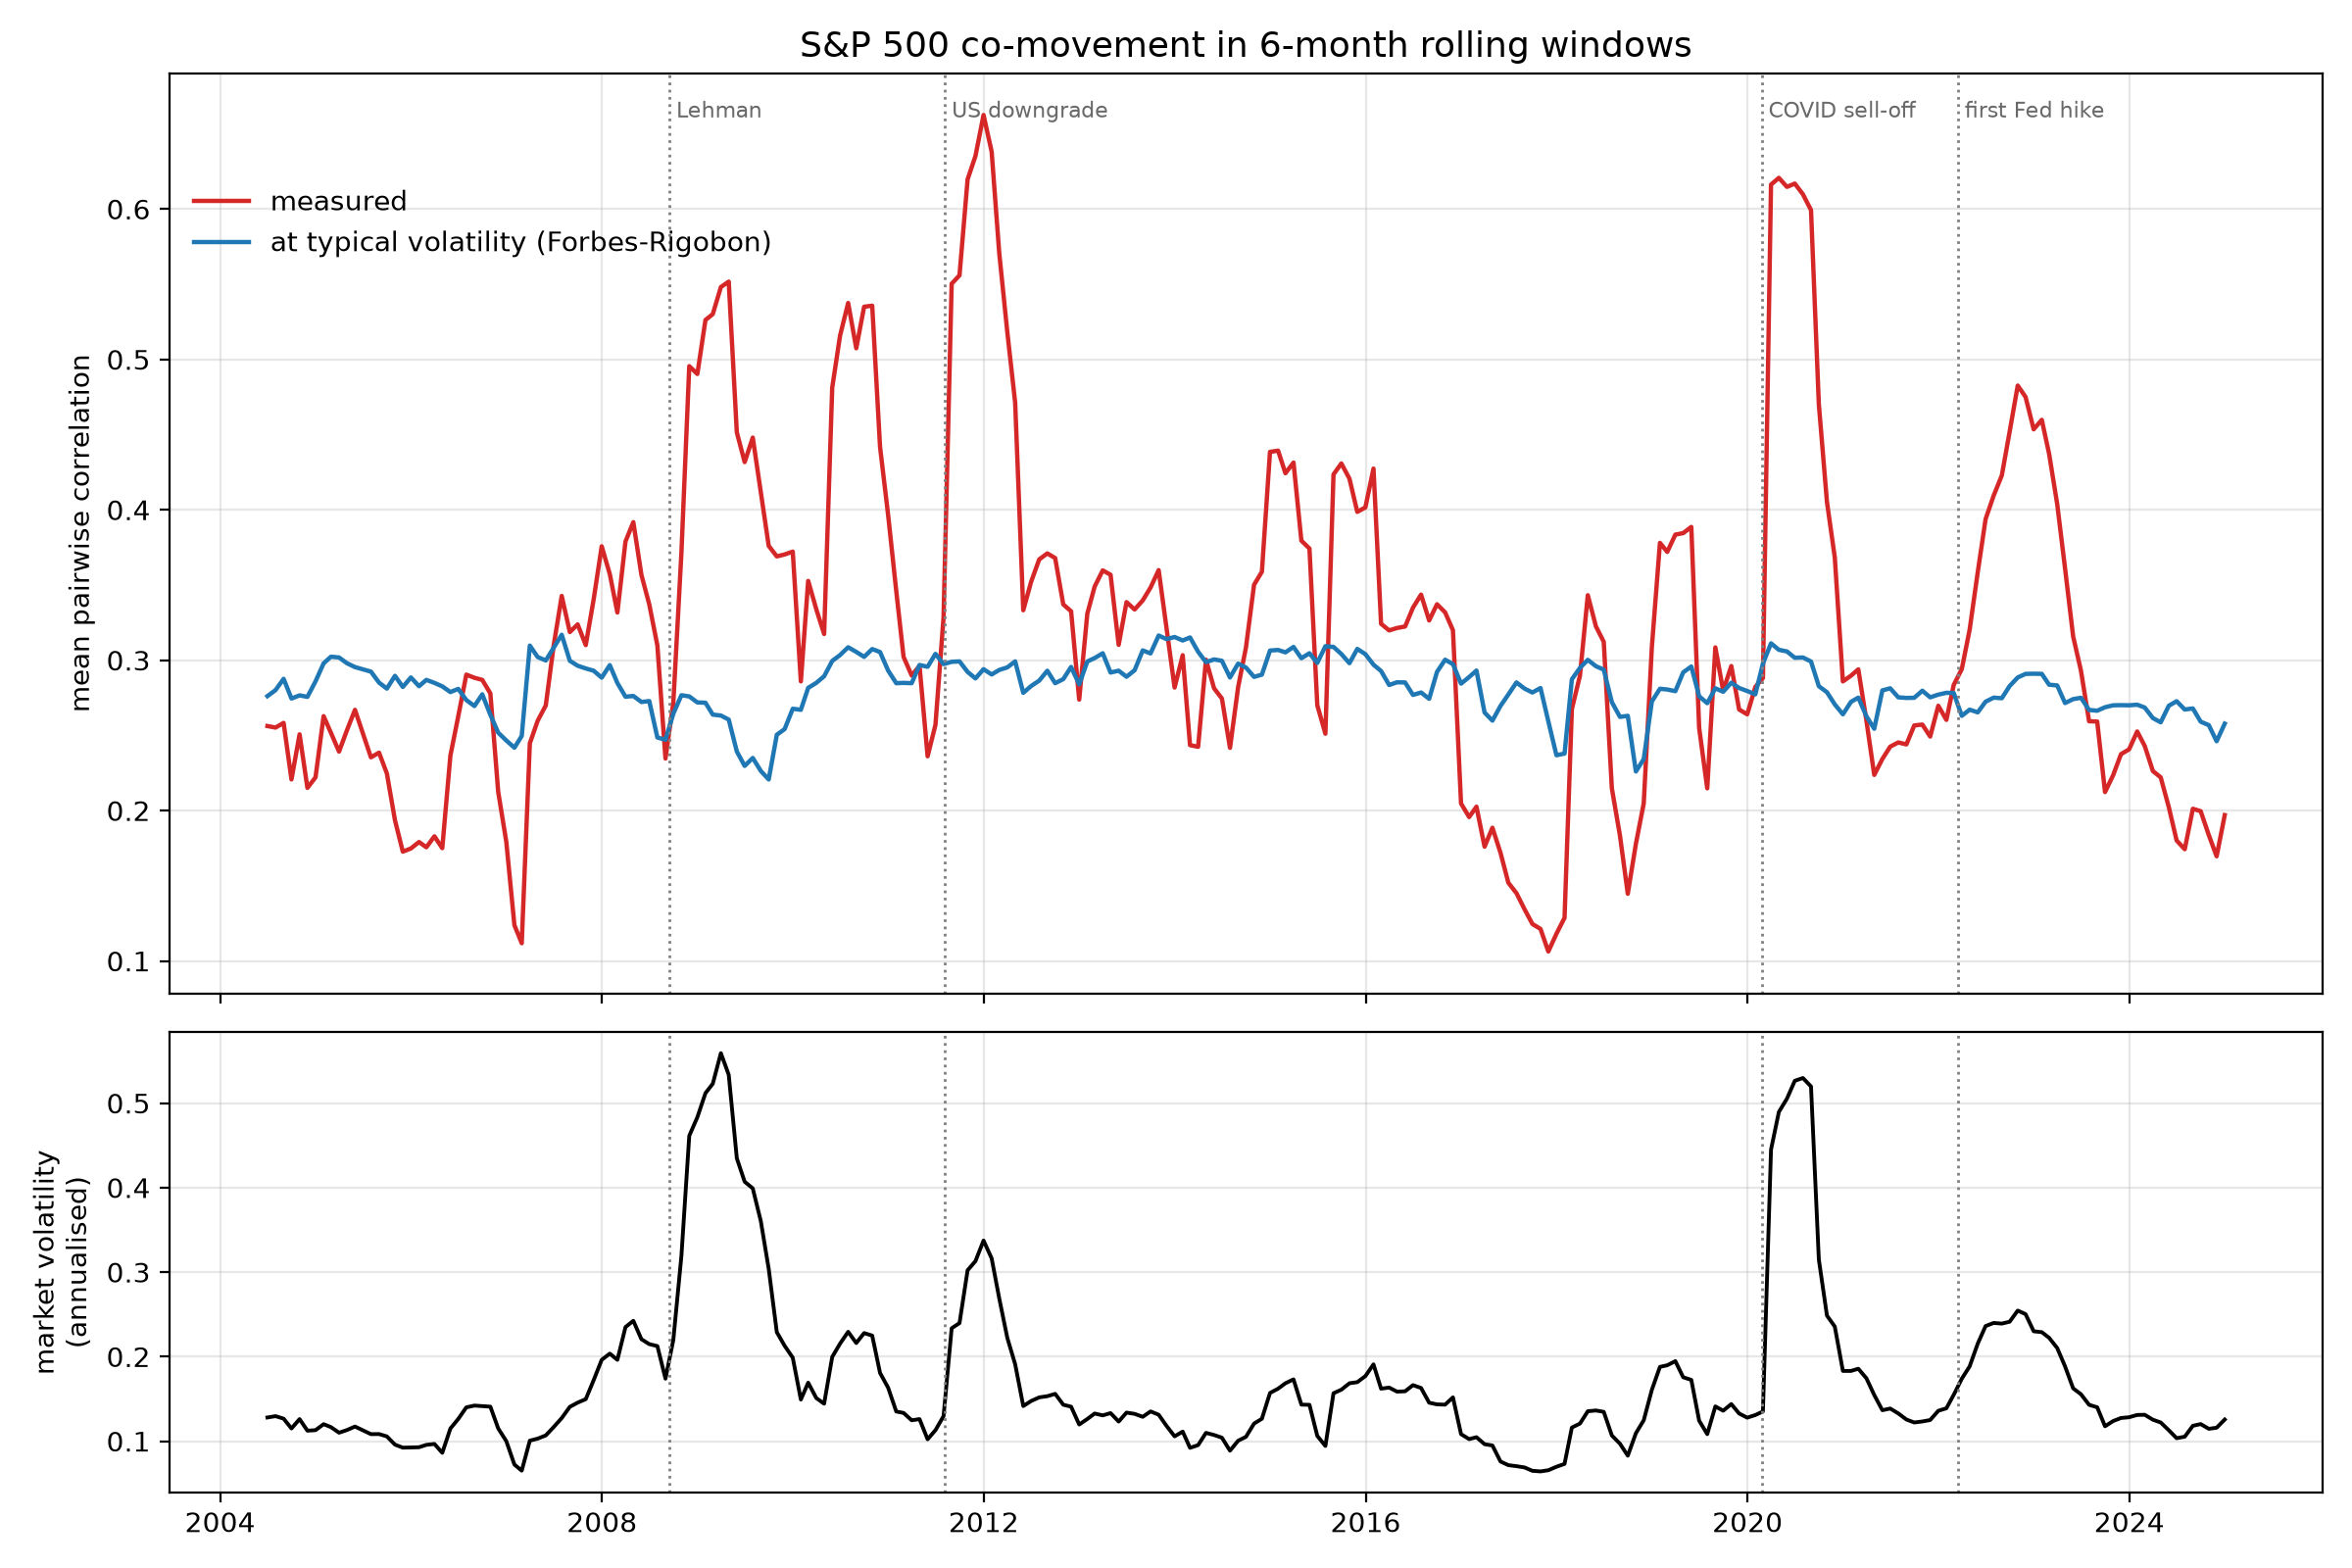

In [3]:
Image(filename="../figures/rolling.png")

In the window ending August 2008 correlation was 0.23, its lowest that year. It rose to 0.37 in the window ending October and 0.50 in November as volatility went from 17% to 46%, so the rise followed Lehman rather than leading it. COVID was faster: from 0.29 in the window ending February 2020 to 0.62 in March. The highest window ends in December 2011 at 0.66.

At typical volatility the rolling series stays between 0.22 and 0.32 throughout. Annualising the volatility matters here: an earlier yearly version used per-observation variances and drifted upwards after 2019, when the data switches from sparse to complete.

## 2. Out-of-sample risk

Two risk models are calibrated on one year and used to predict the next year's volatility of an equal-weight portfolio and a minimum-variance portfolio. The sample model uses that year's covariance matrix. The typical-volatility model keeps that year's betas but resets market and idiosyncratic volatility to their median over the calibration year and the years before it, so it uses no future data. A bias ratio above 1 means the model understated risk.

In [4]:
next_year, from_2017 = oos_risk.main()

calibrated on 2017, equal-weight and minimum-variance portfolios:
      ew_pred_sample  ew_pred_typical  ew_realised  ew_bias_sample  ew_bias_typical  mv_bias_sample  mv_bias_typical
test                                                                                                                
2018           0.071            0.140        0.147           2.063            1.047           4.834            6.504
2019           0.071            0.138        0.124           1.764            0.900           3.710            5.778
2020           0.070            0.137        0.394           5.614            2.876          14.183           17.874
2021           0.070            0.136        0.135           1.940            0.997           4.546            6.049
2022           0.069            0.133        0.221           3.220            1.662           7.494            9.757
2023           0.067            0.130        0.136           2.016            1.044           4.923            6.95

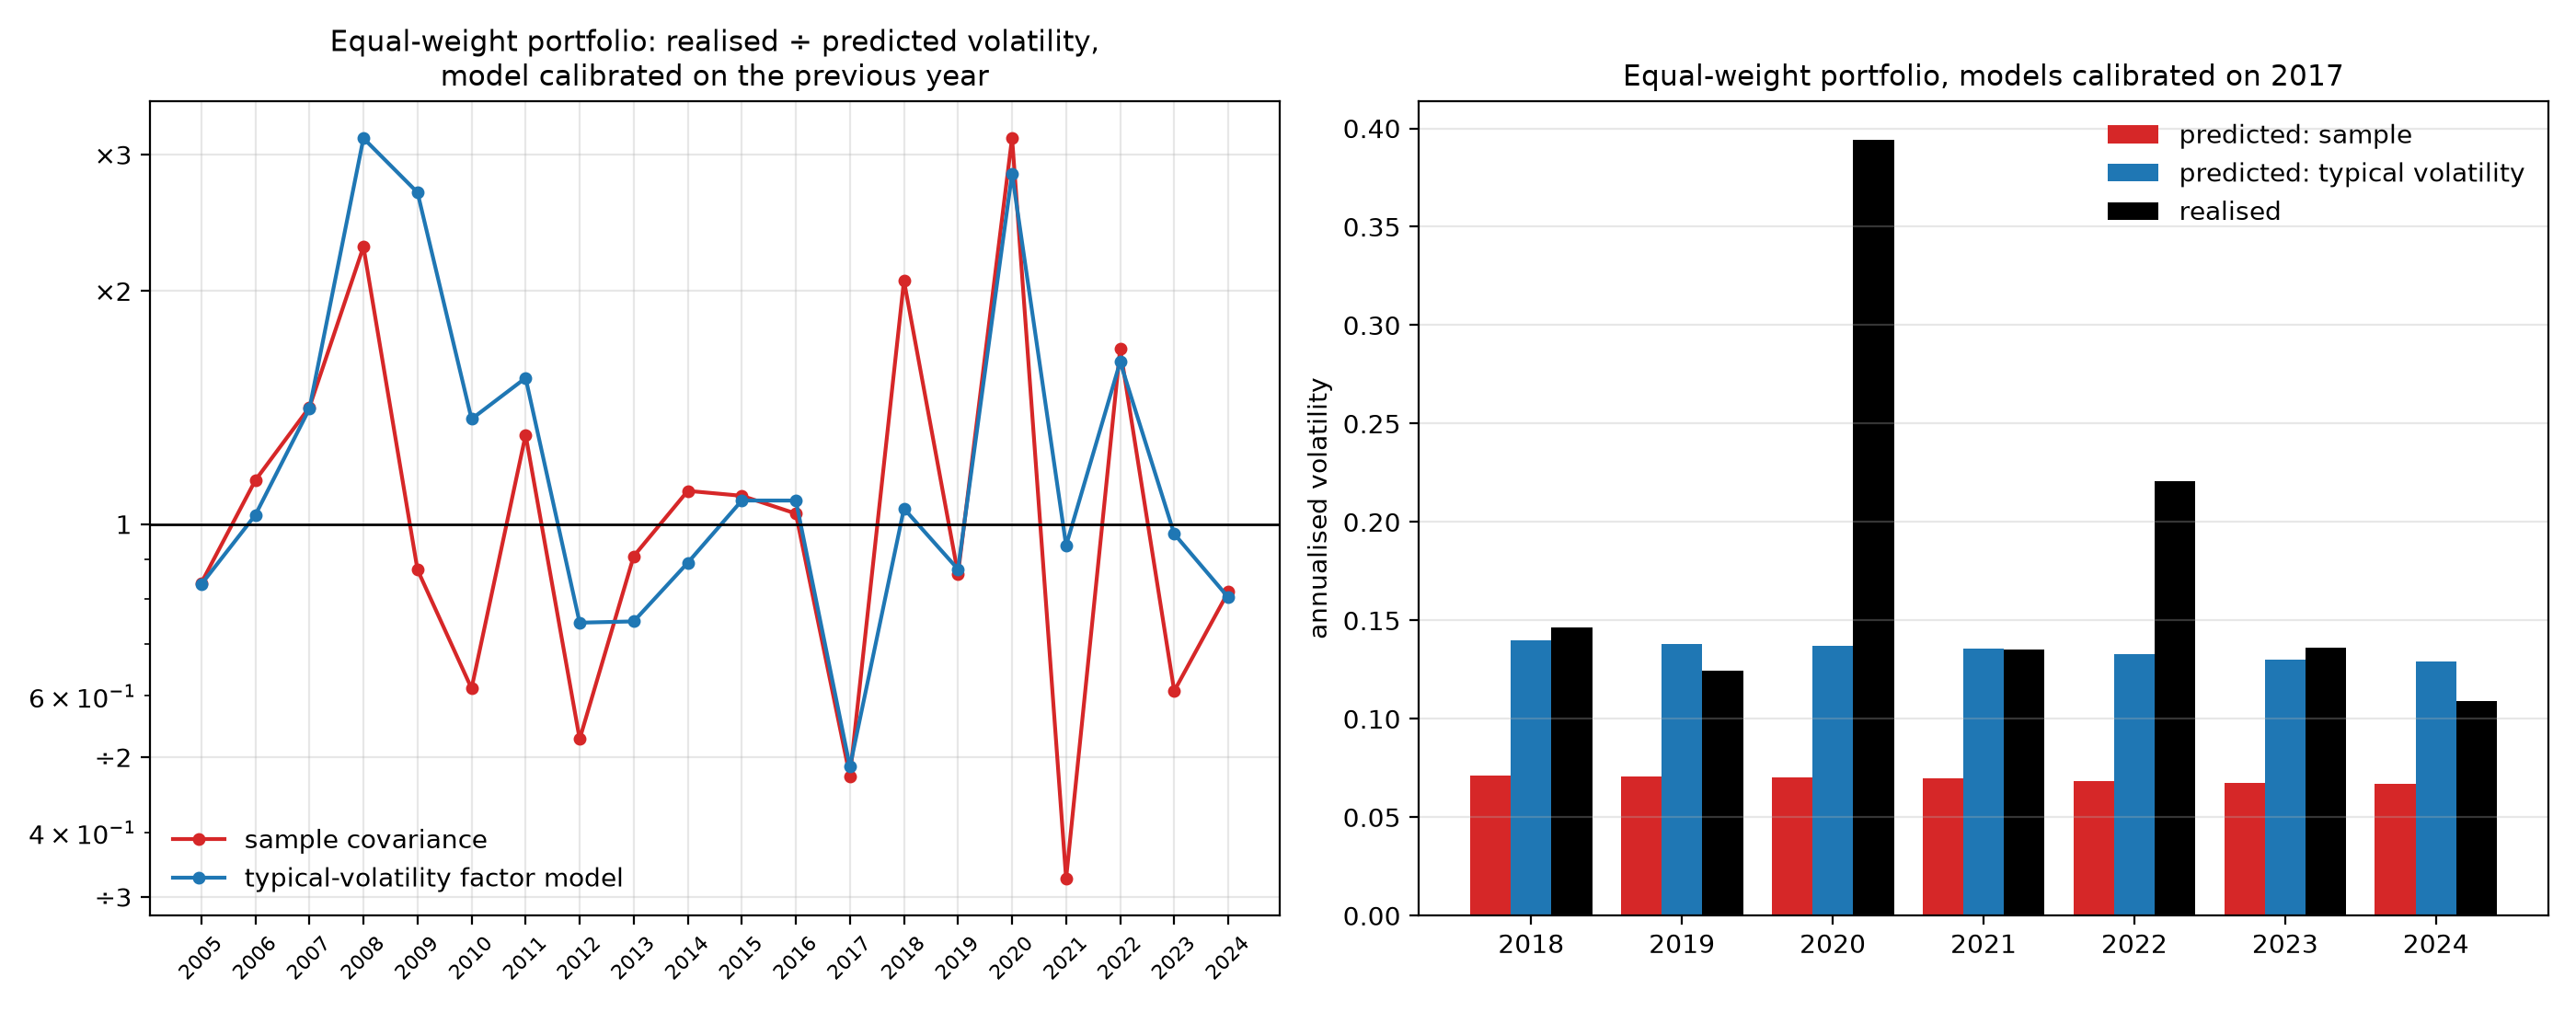

In [5]:
Image(filename="../figures/oos_risk.png")

Calibrated on 2017, the sample model understated the equal-weight portfolio's volatility in every later year: 2.1 times in 2018, 5.6 times in 2020 and 3.2 times in 2022. The typical-volatility model is close in calm years and halves the miss in 2020 and 2022.

Calibrated on the previous year, the typical model is somewhat more accurate on average (mean absolute log bias 0.35 against 0.42), mostly because it avoids overstating risk after a crisis year. Neither model anticipates a crisis: both understate 2008 or 2020 by about 3 times. Minimum-variance portfolios are understated by 1.6 to 18 times in every year, because the optimiser concentrates in stocks that looked quiet in the calibration year.

## 3. Assets outside the index

Total returns of SPY, long Treasuries (TLT), 7-10 year Treasuries (IEF) and gold (GLD) from yfinance.

In [6]:
cross = cross_asset.main()

      SPY_return  TLT_corr  TLT_return  IEF_corr  IEF_return  GLD_corr  GLD_return
year                                                                              
2004       0.107    -0.045       0.100    -0.044       0.050       NaN         NaN
2005       0.048     0.014       0.086    -0.021       0.026     0.004       0.178
2006       0.158     0.046       0.007     0.087       0.025     0.158       0.225
2007       0.051    -0.394       0.103    -0.514       0.104     0.365       0.305
2008      -0.368    -0.487       0.340    -0.473       0.179    -0.000       0.049
2009       0.264    -0.324      -0.218    -0.311      -0.066     0.038       0.240
2010       0.151    -0.552       0.090    -0.518       0.094     0.198       0.293
2011       0.019    -0.708       0.340    -0.680       0.156    -0.028       0.096
2012       0.160    -0.651       0.024    -0.587       0.037     0.254       0.066
2013       0.323    -0.214      -0.134    -0.117      -0.061     0.170      -0.283
2014

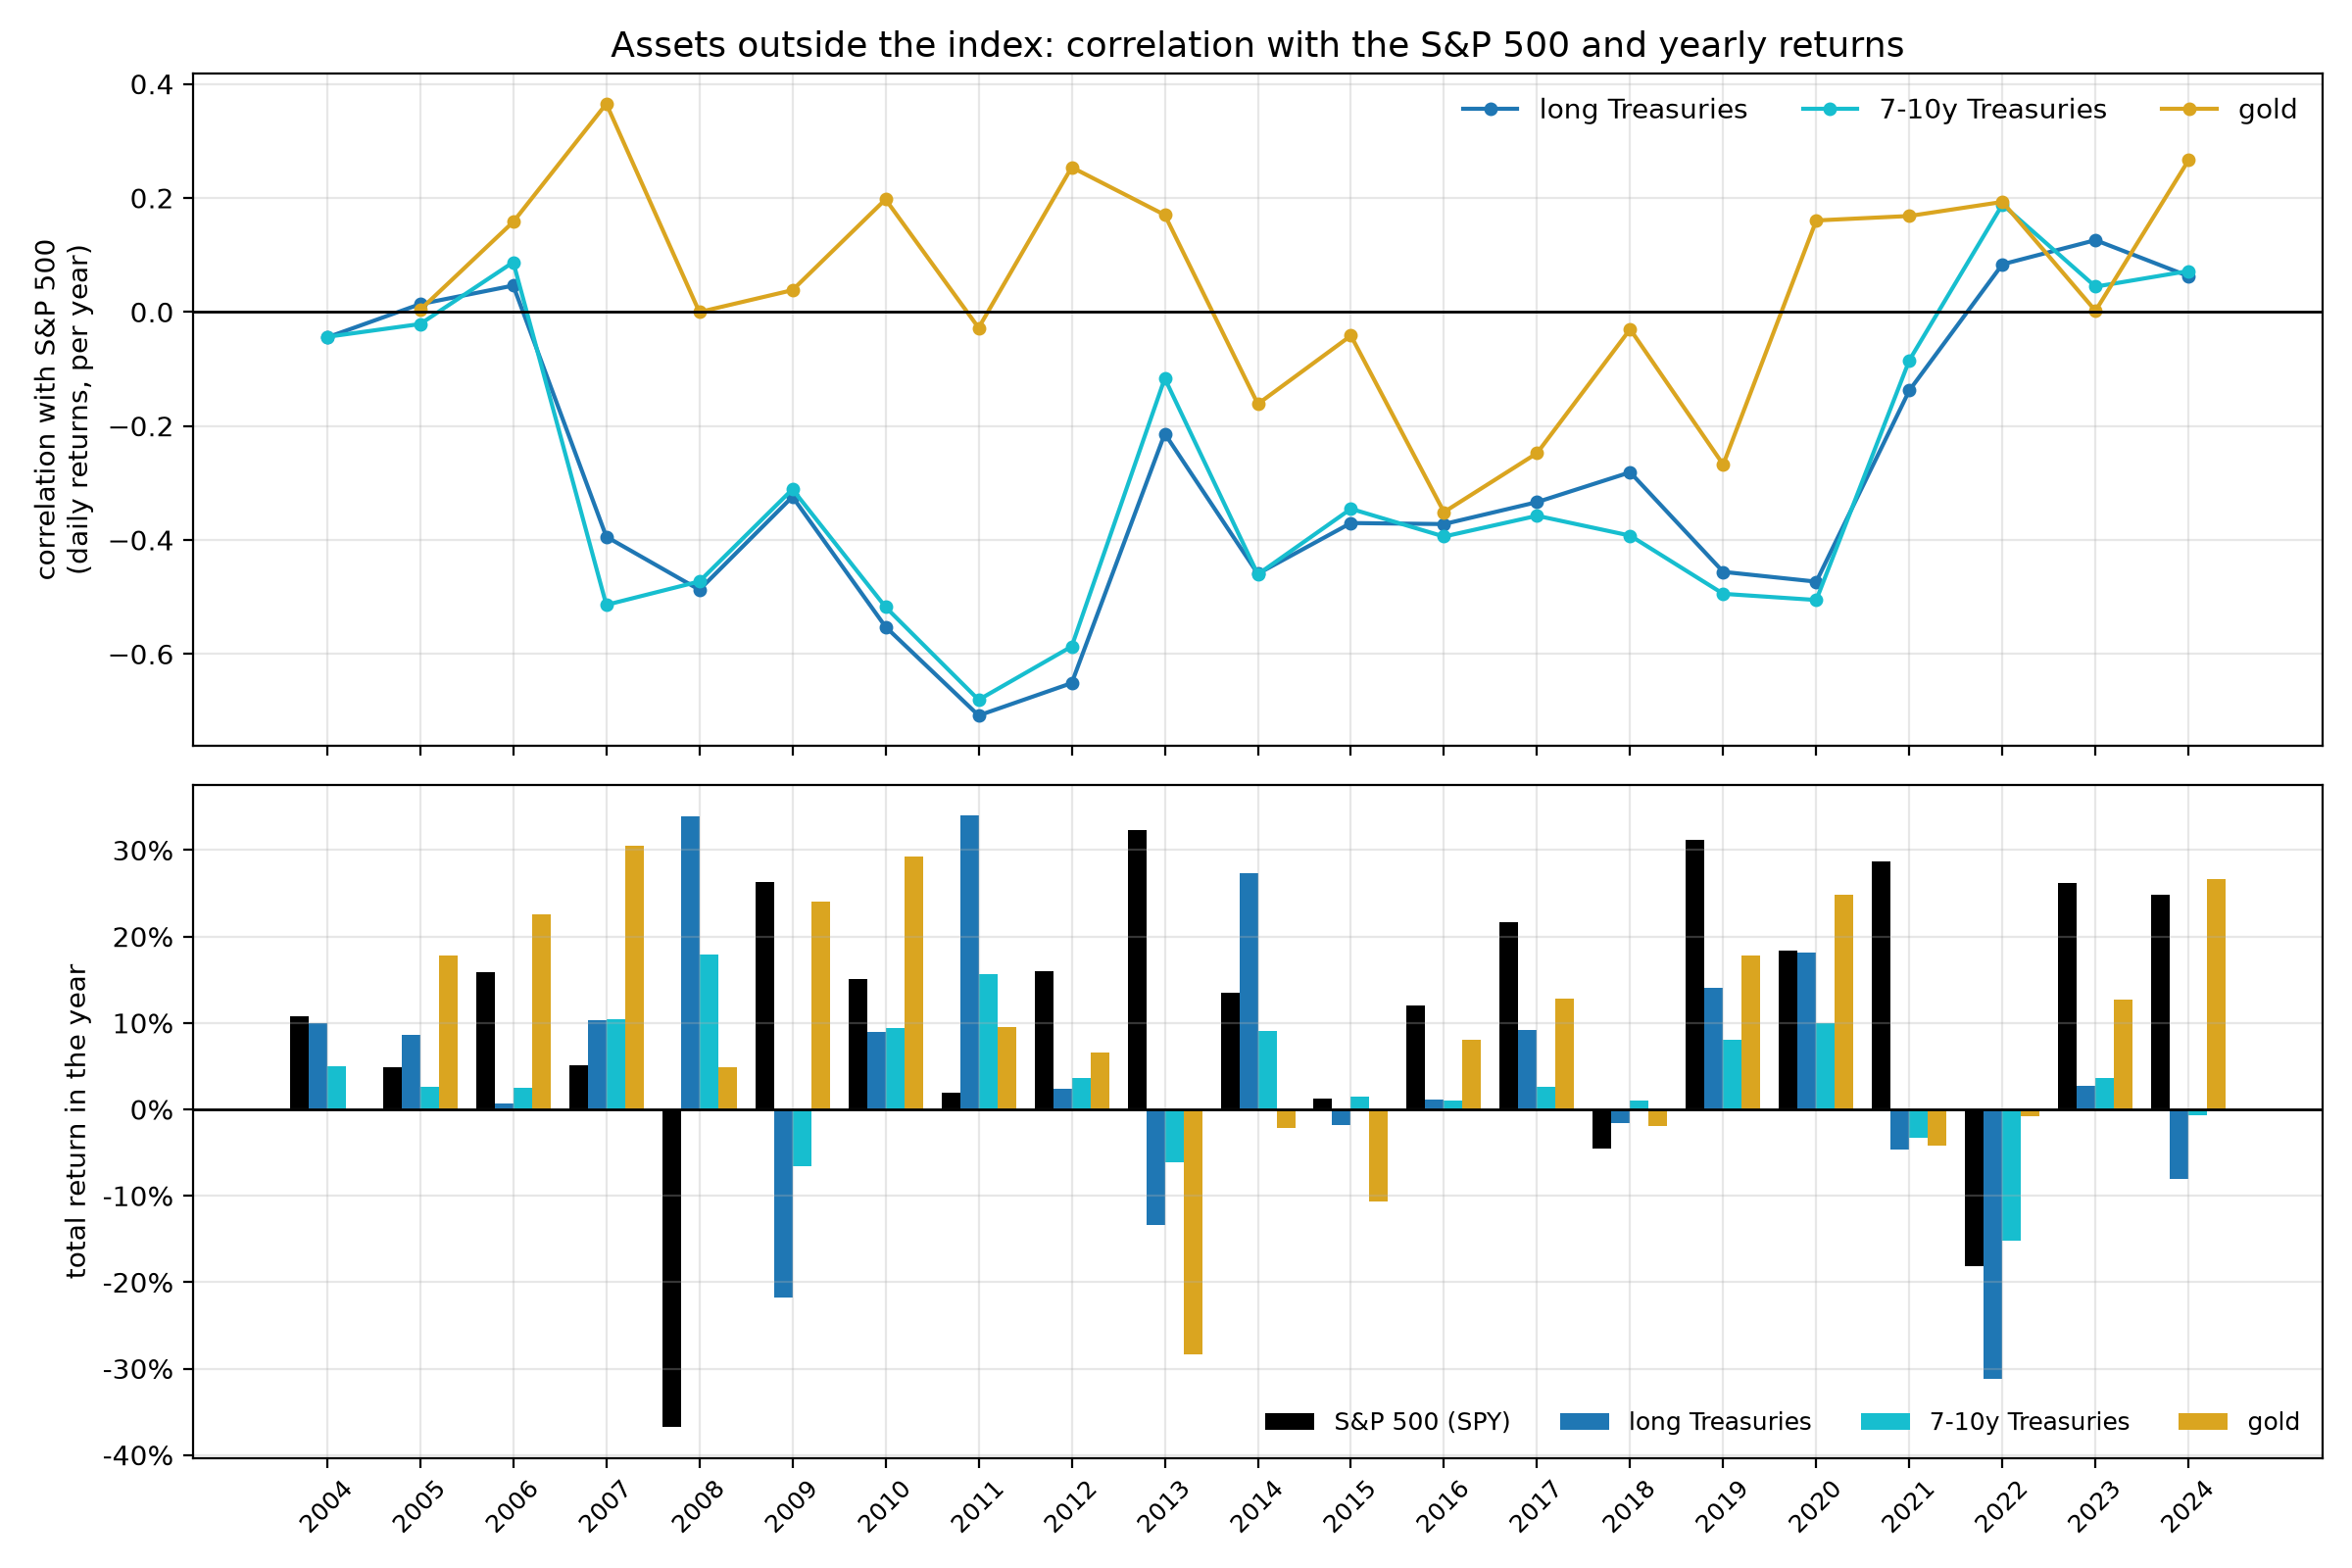

In [7]:
Image(filename="../figures/cross_asset.png")

Treasuries were negatively correlated with the index in most years from 2007 to 2020 and rose when it fell: in 2008 long Treasuries returned +34% against −37% for the S&P 500, and on the index's worst 5% of days since 2004 they averaged +0.86%. In 2022 the correlation turned positive and long Treasuries fell 31%, more than the index. Gold was close to uncorrelated and roughly flat on the worst days. Protection from outside the index depends on what is causing the fall.

## 4. Harder null models

Notebook 06 compares the observed network density with beta-only markets driven by Gaussian noise. Two variants test its main caveats:

- Student-t noise with 4 degrees of freedom: fat tails at the same variance.
- Market plus sector factors: each sector gets its own common factor, fitted by factor analysis on the market residuals. Density above this null is structure that neither the market nor sectors explain.

Each run takes about 30 minutes, so this cell reads the saved results. Run `python -m src.one_factor_null --sims 100 --noise t` and `python -m src.one_factor_null --sims 100 --model sector` to regenerate them.

In [8]:
columns = ["observed_density", "null_mean", "p_excess"]
variants = {"Gaussian": "one_factor_null.csv", "Student-t": "one_factor_null_heterogeneous_t.csv",
            "market + sector": "one_factor_null_sector_gaussian.csv"}
robustness = pd.concat({name: pd.read_csv(f"../figures/{file}", index_col="year")[columns]
                        for name, file in variants.items()}, axis=1)
robustness

Gaussian                           Student-t                     \
     observed_density null_mean p_excess observed_density null_mean p_excess   
year                                                                           
2004           0.0079    0.0000   0.0050           0.0079    0.0023   0.0980   
2005           0.0059    0.0000   0.0050           0.0059    0.0001   0.0196   
2006           0.0082    0.0000   0.0050           0.0082    0.0001   0.0196   
2007           0.0209    0.0006   0.0050           0.0209    0.0041   0.0784   
2008           0.0523    0.0165   0.0249           0.0523    0.0253   0.2245   
2009           0.0486    0.0144   0.0249           0.0486    0.0269   0.1600   
2010           0.0569    0.0384   0.1990           0.0569    0.0414   0.3061   
2011           0.0803    0.0858   0.6598           0.0803    0.0813   0.5652   
2012           0.0211    0.0006   0.0050           0.0211    0.0039   0.0600   
2013           0.0194    0.0004   0.0050           0.0194    0.0034   0.0588   
2014           0.0344    0.0053   0.0100           0.0344    0.0119   0.1176   
2015           0.0297    0.0014   0.0050           0.0297    0.0066   0.0784   
2016           0.0234    0.0001   0.0050           0.0234    0.0010   0.0196   
2017           0.0068    0.0000   0.0050           0.0068    0.0000   0.0196   
2018           0.0244    0.0004   0.0050           0.0244    0.0042   0.0600   
2019           0.0130    0.0000   0.0050           0.0130    0.0000   0.0196   
2020           0.0800    0.0726   0.4129           0.0800    0.0673   0.3673   
2021           0.0161    0.0000   0.0050           0.0161    0.0015   0.0392   
2022           0.0453    0.0025   0.0050           0.0453    0.0126   0.0980   
2023           0.0109    0.0000   0.0050           0.0109    0.0026   0.0784   
2024           0.0059    0.0000   0.0050           0.0059    0.0000   0.0196   

      market + sector                     
     observed_density null_mean p_excess  
year                                      
2004           0.0079    0.0038   0.0588  
2005           0.0059    0.0031   0.0588  
2006           0.0082    0.0054   0.1176  
2007           0.0209    0.0153   0.1765  
2008           0.0523    0.0449   0.3529  
2009           0.0486    0.0472   0.4706  
2010           0.0569    0.0602   0.5882  
2011           0.0803    0.0823   0.6571  
2012           0.0211    0.0160   0.1961  
2013           0.0194    0.0164   0.2745  
2014           0.0344    0.0317   0.3529  
2015           0.0297    0.0245   0.2157  
2016           0.0234    0.0161   0.0588  
2017           0.0068    0.0046   0.0196  
2018           0.0244    0.0210   0.2941  
2019           0.0130    0.0110   0.1569  
2020           0.0800    0.0886   0.8571  
2021           0.0161    0.0114   0.0196  
2022           0.0453    0.0437   0.4706  
2023           0.0109    0.0084   0.0392  
2024           0.0059    0.0048   0.0392

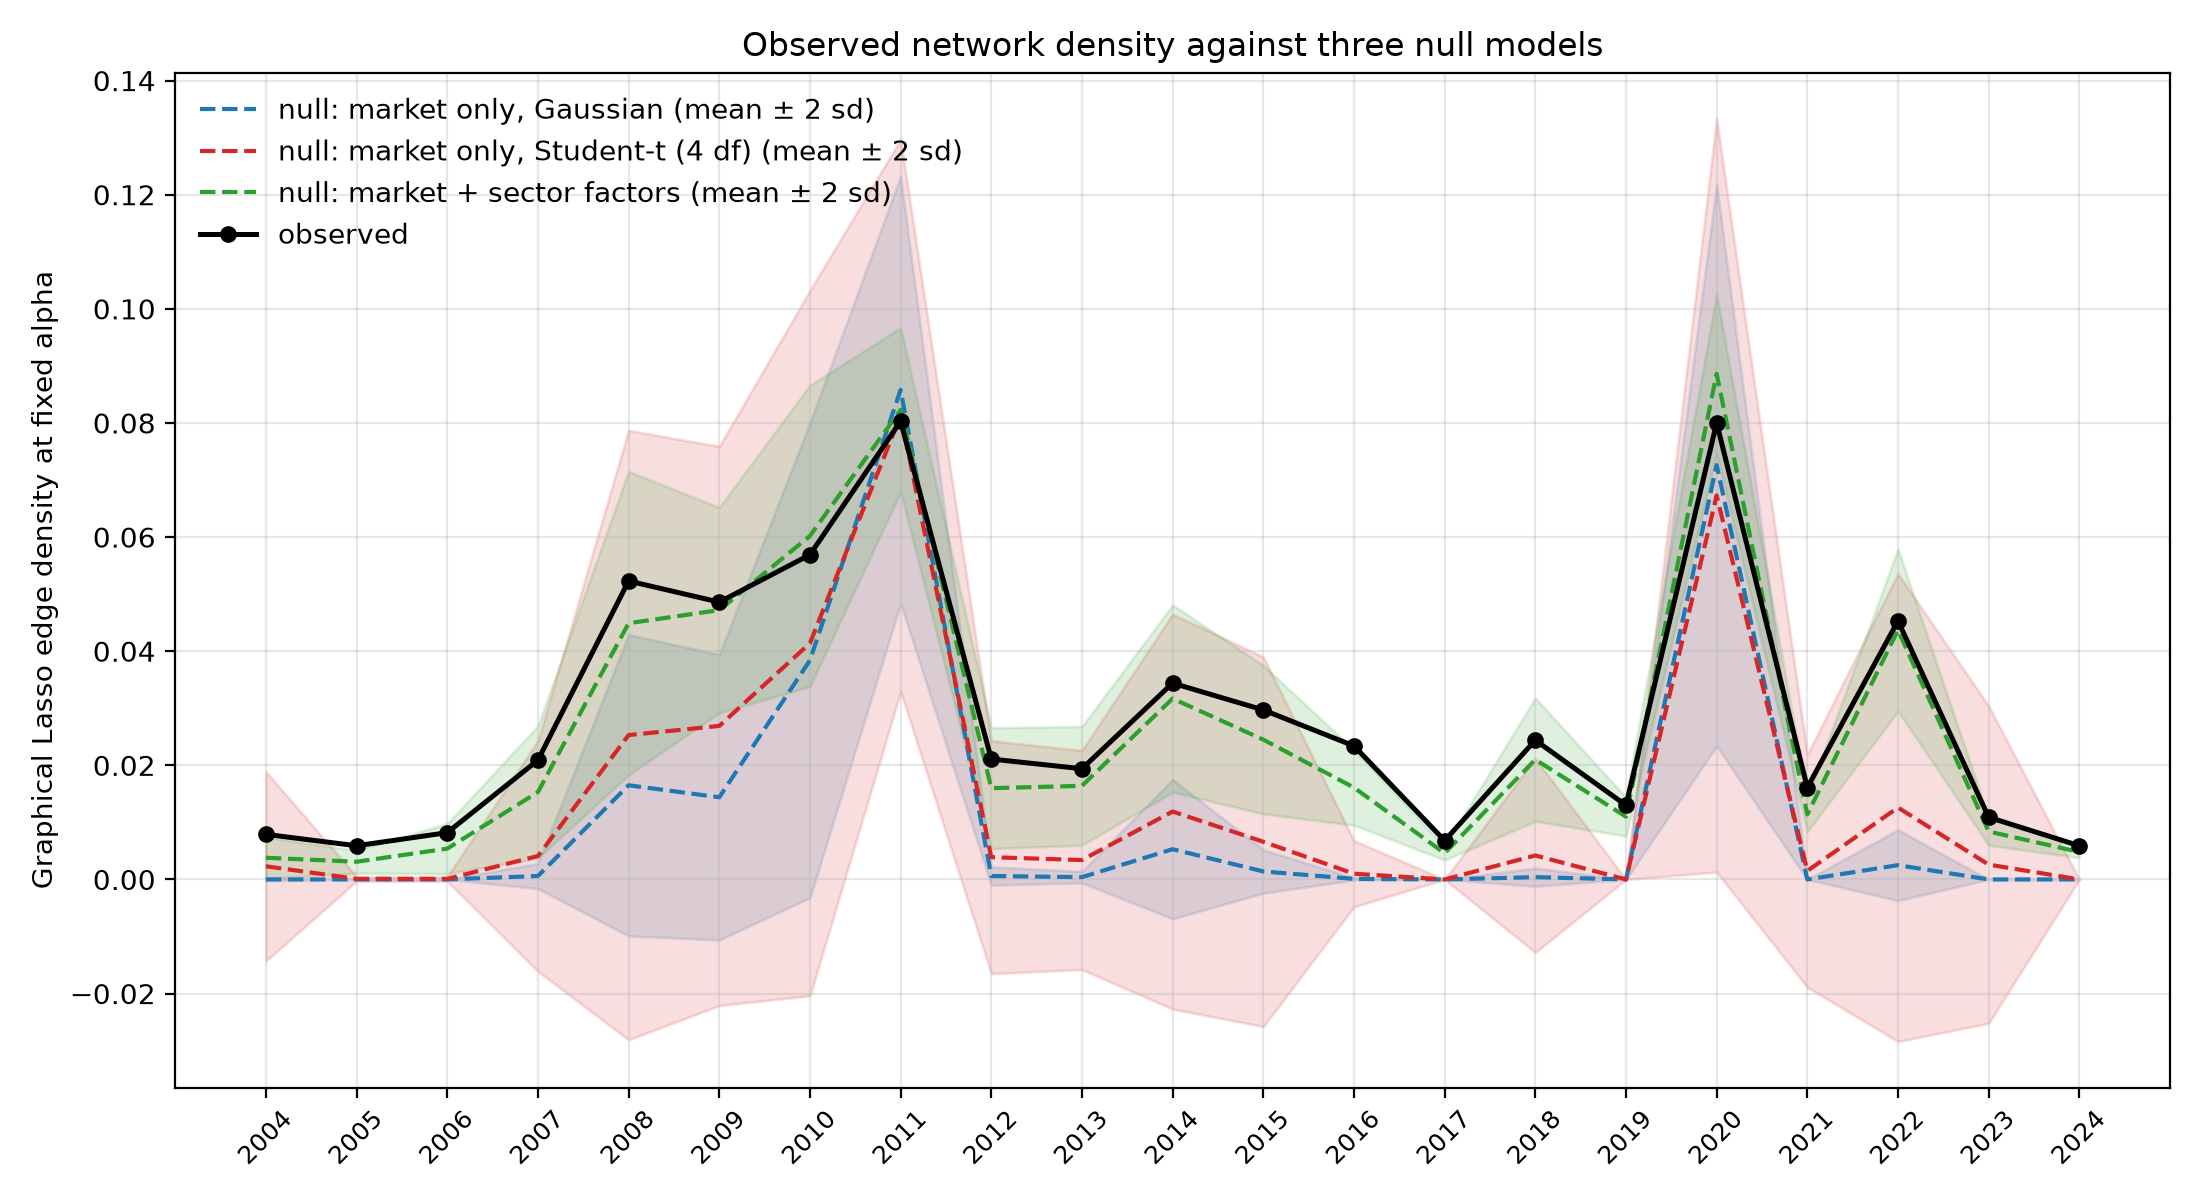

In [9]:
Image(filename="../figures/null_robustness.png")

Fat tails weaken the one-factor test without closing the gap: the average Student-t null is about a fifth of the observed density, but occasional dense draws widen its range, and the excess is significant in 7 of 21 years.

Sector factors do much more. The market-plus-sector null reproduces between half and all of the observed density in every year, and the observed network beats it only in 2017, 2021, 2023 and 2024, by 0.001 to 0.005. The links that survive the one-factor test are mostly sector structure, plus a thin layer of pair-specific links such as share classes and spin-offs.